In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

sns.set_theme(style="whitegrid")

In [2]:
df = pd.read_csv("../dataset/creditcard.csv")

print("Dimensions :", df.shape)
df.head()

Dimensions : (284807, 31)


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


In [3]:
print("Valeurs manquantes :", df.isnull().sum().sum())
print("Doublons :", df.duplicated().sum())

Valeurs manquantes : 0


Doublons : 1081


In [4]:
#nettoyage des doublons
df = df.drop_duplicates()
print("Dimensions après suppression :", df.shape)

Dimensions après suppression : (283726, 31)


In [5]:
#Séparation des variables X et y
X = df.drop("Class", axis=1)
y = df["Class"]

print("Dimensions de X :", X.shape)
print("Dimensions de y :", y.shape)

Dimensions de X : (283726, 30)
Dimensions de y : (283726,)


In [6]:
#Division Train / Test
X_train, X_test, y_train, y_test = train_test_split(X, y,test_size=0.2,random_state=42,stratify=y)           

print("X_train :", X_train.shape)
print("X_test :", X_test.shape)
print("y_train :", y_train.shape)
print("y_test :", y_test.shape)

X_train : (226980, 30)
X_test : (56746, 30)
y_train : (226980,)
y_test : (56746,)


In [7]:
#Normalisation des données
scaler = StandardScaler()

X_train_scaled = X_train.copy()
X_test_scaled = X_test.copy()

columns_to_scale = ["Time", "Amount"]

X_train_scaled[columns_to_scale] = scaler.fit_transform(
    X_train[columns_to_scale]
)

X_test_scaled[columns_to_scale] = scaler.transform(
    X_test[columns_to_scale]
)

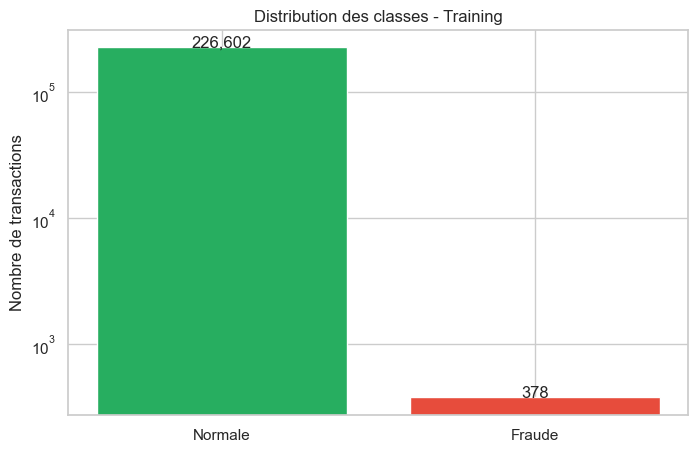

In [8]:
#Vérification du déséquilibre
class_counts = y_train.value_counts().sort_index()

plt.figure(figsize=(8, 5))

bars = plt.bar(
    ["Normale", "Fraude"],
    class_counts.values,
    color=["#27AE60", "#E74C3C"]
)

plt.yscale("log")
plt.title("Distribution des classes - Training")
plt.ylabel("Nombre de transactions")

for bar, value in zip(bars, class_counts.values):
    plt.text(
        bar.get_x() + bar.get_width()/2,
        value,
        f"{value:,}",
        ha="center"
    )

plt.show()

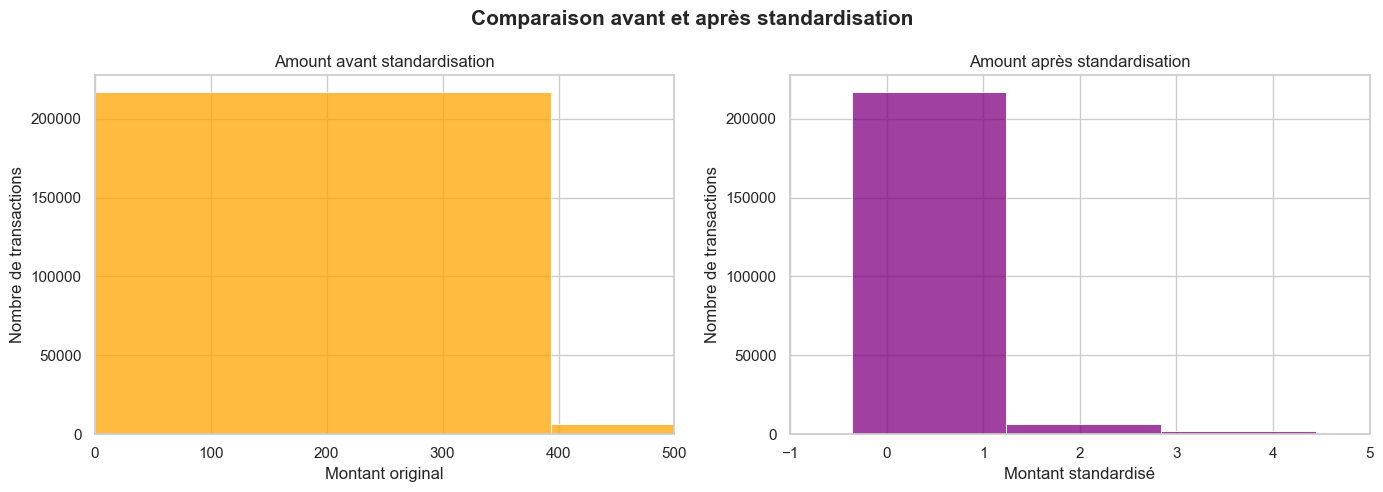

In [9]:
# Comparaison avant / après standardisation de Amount

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Avant standardisation
sns.histplot(X_train["Amount"], bins=50, color="orange", ax=axes[0])
axes[0].set_title("Amount avant standardisation")
axes[0].set_xlabel("Montant original")
axes[0].set_ylabel("Nombre de transactions")
axes[0].set_xlim(0, 500)

# Après standardisation
sns.histplot(X_train_scaled["Amount"], bins=50, color="purple", ax=axes[1])
axes[1].set_title("Amount après standardisation")
axes[1].set_xlabel("Montant standardisé")
axes[1].set_ylabel("Nombre de transactions")
axes[1].set_xlim(-1, 5)

plt.suptitle("Comparaison avant et après standardisation",
             fontsize=15, fontweight="bold")

plt.tight_layout()
plt.show()

In [10]:
#Sauvegarde des données préparées
import os

os.makedirs("../dataset/processed", exist_ok=True)

X_train_scaled.to_csv("../dataset/processed/X_train.csv", index=False)
X_test_scaled.to_csv("../dataset/processed/X_test.csv", index=False)

y_train.to_csv("../dataset/processed/y_train.csv", index=False)
y_test.to_csv("../dataset/processed/y_test.csv", index=False)

print("Données préparées et sauvegardées avec succès !")


Données préparées et sauvegardées avec succès !


## Conclusion

Le preprocessing a permis de :

- Nettoyer les données en supprimant les doublons.
- Séparer les variables explicatives et la variable cible.
- Diviser les données en ensembles d'entraînement et de test.
- Normaliser les variables Time et Amount.
- Préserver la distribution des classes.

Les données sont maintenant prêtes pour l'entraînement
et l'évaluation des modèles.